# TP2 : Apprentissage supervisé — Régression linéaire

Objectif : prédire le prix de location des logements Airbnb du quartier de **Brooklyn** (jeu de données `AB_NYC_2019.csv`).

## 1. Chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv('data/AB_NYC_2019.csv')
print("Taille du jeu complet :", data.shape)
data = data[data['neighbourhood_group'] == 'Brooklyn']
print("Taille (Brooklyn) :", data.shape)
data.head()

Taille du jeu complet : (48895, 16)
Taille (Brooklyn) : (20104, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
6,5121,BlissArtsSpace!,7356,Garon,Brooklyn,Bedford-Stuyvesant,40.68688,-73.95596,Private room,60,45,49,2017-10-05,0.40,1,0
12,5803,"Lovely Room 1, Garden, Best Area, Legal rental",9744,Laurie,Brooklyn,South Slope,40.66829,-73.98779,Private room,89,4,167,2019-06-24,1.34,3,314
15,6848,Only 2 stops to Manhattan studio,15991,Allen & Irina,Brooklyn,Williamsburg,40.70837,-73.95352,Entire home/apt,140,2,148,2019-06-29,1.20,1,46


In [2]:
data[['price', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count']].describe()

,price,number_of_reviews,reviews_per_month,calculated_host_listings_count
count,20104.000000,20104.000000,16447.000000,20104.000000
mean,124.383207,24.202845,1.283212,2.284371
std,186.873538,44.344868,1.516259,5.273758
min,0.000000,0.000000,0.010000,1.000000
25%,60.000000,1.000000,0.180000,1.000000
50%,90.000000,6.000000,0.660000,1.000000
75%,150.000000,25.000000,1.980000,2.000000
max,10000.000000,488.000000,14.000000,232.000000


## 2. Régression linéaire avec une seule variable indépendante

$$y = ax + b,\qquad a = \frac{\sum (x-\bar x)(y-\bar y)}{\sum (x-\bar x)^2},\qquad b = \bar y - a\bar x$$

In [3]:
def calculate_slope(x, y):
    mx = x - x.mean()
    my = y - y.mean()
    return sum(mx * my) / sum(mx**2)

def get_params(x, y):
    a = calculate_slope(x, y)
    b = y.mean() - a * x.mean()
    return a, b

In [4]:
d = data[data.price > 0]
x = d.number_of_reviews
y = np.log(d.price)
a, b = get_params(x, y)
print("a = %.6f, b = %.4f" % (a, b))

lin_reg = a*x + b

a = 0.000681, b = 4.5500


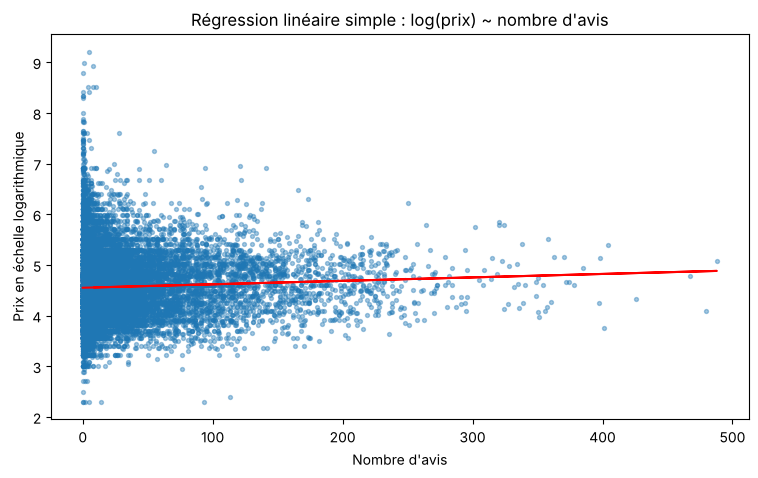

Prédiction pour 0 avis   : log(prix) = 4.55  ->  95 $
Prédiction pour 100 avis : log(prix) = 4.62  ->  101 $


In [5]:
plt.figure(figsize=(9, 5))
plt.xlabel("Nombre d'avis")
plt.ylabel('Prix en échelle logarithmique')
plt.scatter(x, y, s=8, alpha=.4)
plt.plot(x, lin_reg, color='red')
plt.title('Régression linéaire simple : log(prix) ~ nombre d\'avis')
plt.show()

print("Prédiction pour 0 avis   : log(prix) = %.2f  ->  %.0f $" % (b, np.exp(b)))
print("Prédiction pour 100 avis : log(prix) = %.2f  ->  %.0f $" % (a*100 + b, np.exp(a*100 + b)))

In [6]:
# Vérification avec numpy.polyfit
print(np.polyfit(x, y, 1))

[6.80780975e-04 4.55002748e+00]


La droite est quasiment horizontale : la prédiction reste autour de **4,6** (≈ **100 $**) quel que soit le nombre d'avis. Une seule variable ne suffit donc pas.

## 3. Régression linéaire à plusieurs variables avec Scikit-learn

In [7]:
d = data[data.price > 0].copy()
d['reviews_per_month'] = d['reviews_per_month'].fillna(0)

x = d.loc[:, ('reviews_per_month', 'calculated_host_listings_count', 'number_of_reviews')]
# Comme dans la partie 1, on travaille sur le logarithme du prix
y = np.log(d.loc[:, 'price'])
print(x.shape, y.shape)

(20095, 3) (20095,)


In [8]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("train :", x_train.shape, " test :", x_test.shape)

train : (16076, 3)  test : (4019, 3)


In [9]:
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(x_train, y_train)
print("Coefficients :", {c: round(float(v), 5) for c, v in zip(x.columns, model.coef_)})
print("Ordonnée à l'origine :", round(float(model.intercept_), 4))

Coefficients : {'reviews_per_month': -0.01902, 'calculated_host_listings_count': -0.00748, 'number_of_reviews': 0.00103}
Ordonnée à l'origine : 4.5773


In [10]:
y_pred = model.predict(x_test)
print(y_pred)

[4.56233471 4.57046865 4.58318484 ... 4.57046865 4.69561509 4.56981912]


## 4. Métriques de qualité (MSE, MAE)

$$MSE = \frac{1}{n}\sum (y_i - \hat y_i)^2 \qquad MAE = \frac{1}{n}\sum |y_i - \hat y_i|$$

On revient à l'échelle des dollars avant de calculer les métriques.

In [11]:
y_test = np.exp(y_test)
y_pred = np.exp(y_pred)

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print('mse: %.3f, mae: %.3f' % (mse, mae))
print('rmse: %.3f $' % np.sqrt(mse))

mse: 24189.448, mae: 62.854
rmse: 155.530 $


In [12]:
comparaison = pd.DataFrame({'prix_reel': y_test.values, 'prix_predit': y_pred.round(2)}).head(10)
comparaison

,prix_reel,prix_predit
0,650.0,95.81
1,150.0,96.59
2,100.0,97.83
3,550.0,95.80
4,78.0,96.52
5,60.0,96.62
6,80.0,96.53
7,500.0,97.27
8,95.0,96.54
9,160.0,97.89


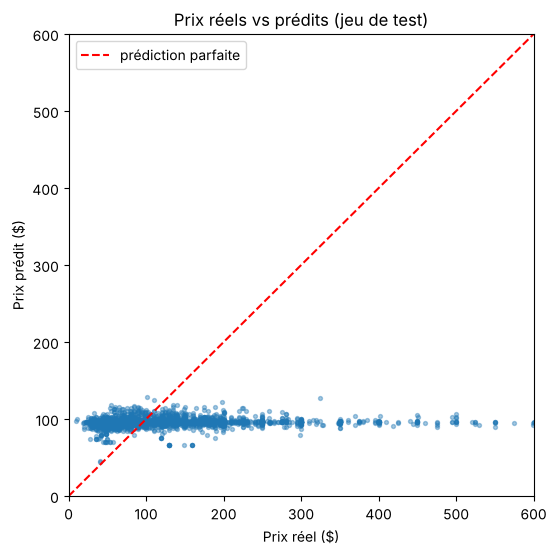

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=8, alpha=.4)
lim = [0, 600]
plt.plot(lim, lim, 'r--', label='prédiction parfaite')
plt.xlim(lim); plt.ylim(lim)
plt.xlabel('Prix réel ($)'); plt.ylabel('Prix prédit ($)')
plt.title('Prix réels vs prédits (jeu de test)'); plt.legend()
plt.show()

## 5. Remarque sur le résultat de l'énoncé

Dans l'énoncé, `y = d.loc[:, 'price']` (prix **non** logarithmique) puis `np.exp(y_pred)` : on applique l'exponentielle à des prix en dollars, ce qui donne des nombres énormes (mse ≈ 1e26). Ici on garde `y = log(price)` comme dans la partie 1, ce qui donne des erreurs interprétables en dollars.

## Conclusion

- La régression simple (nombre d'avis) donne une droite presque horizontale : prédiction constante ≈ 100 $.
- La régression multiple sur 3 variables reste faible : MAE ≈ 63 $, RMSE ≈ 156 $, et les prédictions restent toutes proches de 96 $. Ces variables expliquent mal le prix ; il faudrait ajouter des variables comme `room_type`, `neighbourhood`, `latitude`/`longitude` ou `minimum_nights`.